# Arc and Distance Calculations

## Imports

In [18]:
# Import standard data prep and eda libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
import ipywidgets as widgets
from IPython.display import display
from shapely.ops import nearest_points
from shapely.geometry import LineString
import random



## Data Mapping for Eventual Distance Calculations

| Feature | Role | Source file | Status |
|---|---|---|---|
| Hatcheries | Supply | `trout_hatcheries.gpkg` | Processed data folder |
| Coop Nurseries | Supply | `coop_nurseries.geojson` | Raw Data |
| Class A Streams | Demand | `pa_class_a_trout_streams.gpkg` | Raw Data |
| Stocked Trout Streams | Demand | `pa_stocked_trout_streams.gpkg` | Raw data |
| Roads | Arc | TBD | WIP |


## Goal: Matrix of distance from Hatchery/Coop to Stream, using roads as arc


In [10]:
CRS_M = 5070          # CONUS Albers, meters
N_NEAREST = 2


# Import all layers in the same projected CRS for mapping and distance calculations.
hatcheries = gpd.read_file("../data/processed/trout_hatcheries.gpkg").to_crs(CRS_M)
coop_nurseries = gpd.read_file("../data/raw/Coop_nurseries.geojson").to_crs(CRS_M)
class_a = gpd.read_file("../data/raw/pa_class_a_trout_streams.gpkg").to_crs(CRS_M)
stocked_trout = gpd.read_file("../data/raw/pa_stocked_trout_streams.gpkg").to_crs(CRS_M)
pa_boundary = gpd.read_file("../data/raw/pa_boundary.gpkg").to_crs(CRS_M)

### Plot Nodes

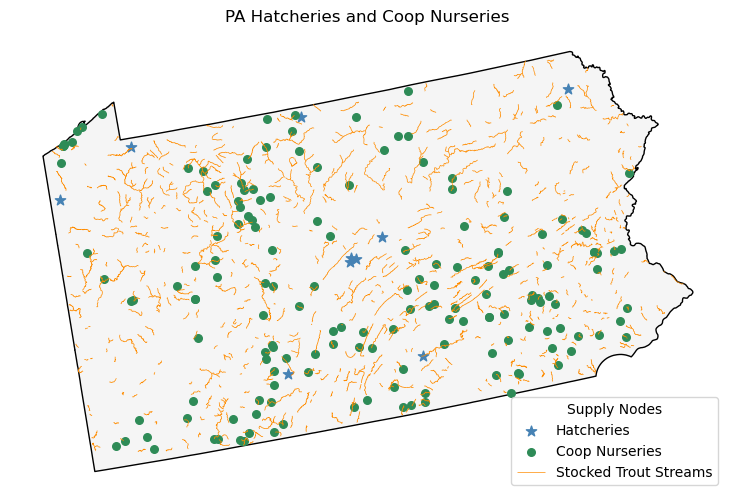

In [11]:
# Show hatcheries and coop nurseries on the map with distinct symbols.
fig, ax = plt.subplots(figsize=(10, 6))
pa_boundary.plot(ax=ax, color="whitesmoke", edgecolor="black")

hatcheries.plot(
    ax=ax,
    marker="*",
    color="steelblue",
    markersize=60,
    label="Hatcheries",
)
coop_nurseries.plot(
    ax=ax,
    marker="o",
    color="seagreen",
    markersize=30,
    label="Coop Nurseries",
)


stocked_trout.plot(
    ax=ax,
    color="darkorange",
    linewidth=0.5,
    label="Stocked Trout Streams",
)

ax.set_title("PA Hatcheries and Coop Nurseries")
ax.legend(title="Supply Nodes")
ax.set_axis_off()
plt.show()

## Calculate Distance from Supply Node to Demand Node, using Roads as Arcs

### Coop Nurseries to Stocked Steams - Closest 2 streams

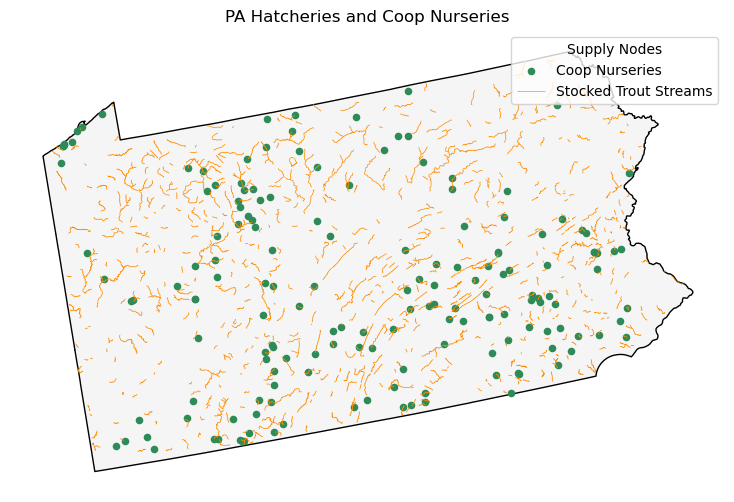

In [12]:
# Show hatcheries and coop nurseries on the map with distinct symbols.
fig, ax = plt.subplots(figsize=(10, 6))
pa_boundary.plot(ax=ax, color="whitesmoke", edgecolor="black")

coop_nurseries.plot(
    ax=ax,
    marker="o",
    color="seagreen",
    markersize=20,
    label="Coop Nurseries",
)


stocked_trout.plot(
    ax=ax,
    color="darkorange",
    linewidth=0.5,
    label="Stocked Trout Streams",
)

ax.set_title("PA Hatcheries and Coop Nurseries")
ax.legend(title="Supply Nodes")
ax.set_axis_off()
plt.show()

In [13]:
# For each coop nursery, find the N closest stream sections in linear distance
rows = []
for h in coop_nurseries.itertuples():
    d = stocked_trout.distance(h.geometry)                 # meters, to nearest point on each line
    near = (stocked_trout.assign(dist_m=d)
                   .sort_values("dist_m")
                   #.drop_duplicates("GlobalID")         # one row per stream, not per section
                   .head(N_NEAREST))
    for rank, s in enumerate(near.itertuples(), start=1):
        rows.append({
            "nursery_id": h.ID,
            "global_id": s.GlobalID,
            "nursery": h.NURSERY_NA,
            "county": h.COUNTY,
            "rank": rank,
            #"stream": s.GNIS_Name,
            "dist_km": round(s.dist_m / 1000, 2),
        })

# Put col global_id next to nursey_id col
result = pd.DataFrame(rows)

result = pd.DataFrame(rows)
result.to_csv("../data/interim/coop_nurseries_nearest_streams.csv", index=False)

In [14]:
result

,nursery_id,global_id,nursery,county,rank,dist_km
0,142,{A8A5CFBE-7A46-4E26-B3DF-1CE8F3757E05},S.O.N.S,Erie,1,1.32
1,142,{67F533F7-FB80-4E83-AC05-A11C55C7980D},S.O.N.S,Erie,2,15.71
2,203,{67734408-165C-4F5B-A33A-50F3241C3AB5},PA Striped Bass,Huntingdon,1,7.74
3,203,{821ACFAE-0029-4BB0-BB69-E6BAF7C95B64},PA Striped Bass,Huntingdon,2,8.30
4,212,{D649F898-D5C7-49D0-859B-F944E040A809},Traditional Anglers of PA H/O Pond,Cambria,1,3.91
...,...,...,...,...,...,...
325,207,{0AFD789C-8E43-4ABF-95AB-4F9BF53C2958},BMS Fisheries Program Nursery,Butler,2,1.43
326,218,{F5B83AF3-99BD-4009-AD14-A92F24315BDD},Shanksville School,Somerset,1,0.59
327,218,{035DEB8E-8B05-46ED-82A1-52326810C82E},Shanksville School,Somerset,2,7.51
328,23,{A80640A2-A818-4D2A-B7C1-7EA7F810E768},Blairs Mills,Huntingdon,1,0.03


### Review Nursey Linear Distance Results (Top 2 Matching)

Closest: Rattling Creek — 0.0 km to nearest stream


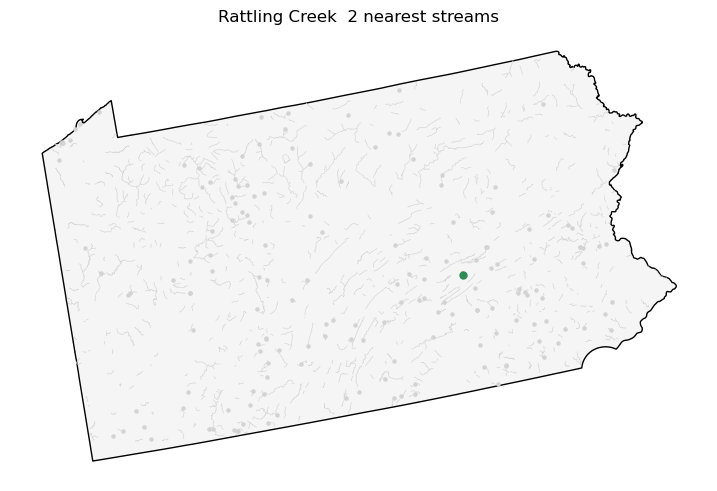

In [22]:


def plot_nursery(nursery_name):
    h = coop_nurseries.loc[
        coop_nurseries["NURSERY_NA"] == nursery_name
    ].iloc[0]
    near = result.loc[
        result["nursery"] == nursery_name
    ].sort_values("rank")

    fig, ax = plt.subplots(figsize=(9, 7))
    pa_boundary.plot(ax=ax, color="whitesmoke", edgecolor="black", zorder=0)
    stocked_trout.plot(ax=ax, color="lightgray", linewidth=0.4, zorder=1)
    coop_nurseries.plot(ax=ax, color="lightgray", markersize=5, zorder=2)
    coop_nurseries.loc[
        coop_nurseries["NURSERY_NA"] == nursery_name
    ].plot(ax=ax, color="seagreen", markersize=25, zorder=4)

    cmap = plt.cm.autumn_r
    for row in near.itertuples():
        stream_geom = stocked_trout.loc[
            stocked_trout["GlobalID"] == row.global_id
        ]
        color = cmap(0.3 + 0.5 / row.rank)
        stream_geom.plot(ax=ax, color=color, linewidth=2.5, zorder=3)
        nearest_on_stream = nearest_points(
            h.geometry, stream_geom.geometry.union_all()
        )[1]
        arc = LineString([h.geometry, nearest_on_stream])
        gpd.GeoSeries([arc], crs=CRS_M).plot(
            ax=ax, color=color, linewidth=1.5, linestyle="--", zorder=3,
        )

    ax.set_title(f"{nursery_name}  {N_NEAREST} nearest streams")
    ax.set_axis_off()
    plt.show()


def plot_random_nursery():
    """Pick a random nursery and plot it."""
    name = random.choice(coop_nurseries["NURSERY_NA"].dropna().unique().tolist())
    plot_nursery(name)


def plot_by_global_id(global_id):
    """Plot whichever nursery has the given nearest-stream global_id in `result`."""
    match = result.loc[result["global_id"] == global_id]
    if match.empty:
        raise ValueError(f"global_id {global_id!r} not found in result")
    plot_nursery(match.iloc[0]["nursery"])


def plot_farthest_nursery():
    """Plot the nursery whose closest stream is farthest away."""
    row = result.loc[result["rank"] == 1].sort_values("dist_km", ascending=False).iloc[0]
    print(f"Farthest: {row['nursery']} — {row['dist_km']} km to nearest stream")
    plot_nursery(row["nursery"])


def plot_closest_nursery():
    """Plot the nursery whose closest stream is nearest of all."""
    row = result.loc[result["rank"] == 1].sort_values("dist_km", ascending=True).iloc[0]
    print(f"Closest: {row['nursery']} — {row['dist_km']} km to nearest stream")
    plot_nursery(row["nursery"])


# --- run one of these ---
#plot_random_nursery()
# plot_by_global_id("{SOME-GUID-HERE}")
#plot_nursery("3 C's Trout")
#plot_farthest_nursery()
plot_closest_nursery()